# Practical Assignment 6: Customer Segmentation using K-Means
**Aim:** Identify natural customer groups from age, annual income and spending score; select K, evaluate quality, profile clusters, and test the effect of scaling.

**Data:** Reproducible *synthetic* retail-mall customer dataset (330 customers), generated below; no external download required. The four source distributions are used only to simulate realistic customers; no labels are supplied to K-Means.

## 1. Import libraries and generate customer data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
profiles = [(24,28,78,85),(46,82,83,80),(38,87,22,80),(55,31,25,85)]
parts = [rng.normal([age, income, spend], [7,11,12], size=(n,3)) for age,income,spend,n in profiles]
a = np.vstack(parts)
a[:,0] = np.clip(a[:,0],18,70)
a[:,1] = np.clip(a[:,1],15,140)
a[:,2] = np.clip(a[:,2],1,100)
df = pd.DataFrame({'Age':np.rint(a[:,0]).astype(int),
                   'Annual Income (k$)':np.round(a[:,1],1),
                   'Spending Score (1-100)':np.rint(a[:,2]).astype(int)})
df.insert(0,'CustomerID',np.arange(1,len(df)+1))
print('Shape:',df.shape)
display(df.head())

Shape: (330, 4)


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,26,16.6,87
1,2,31,15.0,62
2,3,25,24.5,78
3,4,18,37.7,87
4,5,24,40.4,84


## 2. Explore data and check missing values
CustomerID is an identifier and must not be used as a clustering feature.

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,330.000000,330.000000,330.000000,330.000000
mean,165.500000,40.721212,56.016970,51.293939
std,95.407023,13.658932,28.992849,31.435778
min,1.000000,18.000000,15.000000,1.000000
25%,83.250000,29.000000,28.850000,22.250000
50%,165.500000,42.000000,50.900000,51.500000
75%,247.750000,52.000000,82.775000,81.000000
max,330.000000,70.000000,115.000000,100.000000


Missing values per column:
 CustomerID                0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicate rows: 0


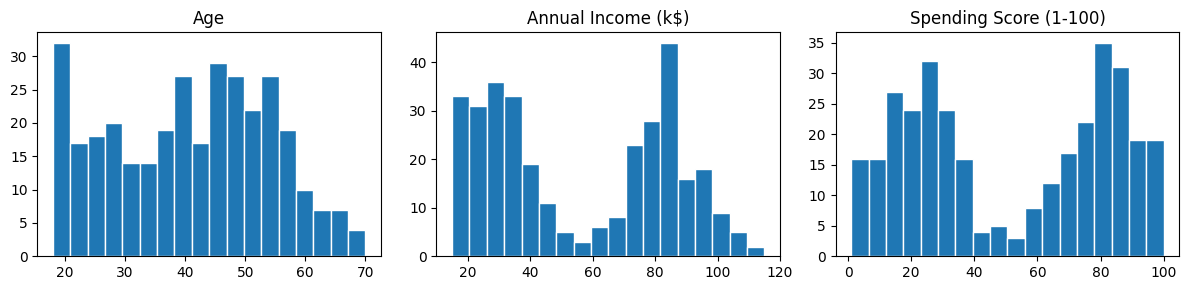

In [2]:
display(df.describe())
print('Missing values per column:\n',df.isna().sum())
print('Duplicate rows:',df.duplicated().sum())
fig, axes = plt.subplots(1,3,figsize=(12,3))
for ax, col in zip(axes,['Age','Annual Income (k$)','Spending Score (1-100)']):
    ax.hist(df[col],bins=18,edgecolor='white'); ax.set_title(col)
plt.tight_layout();plt.show()

## 3. Standardize features
`StandardScaler` transforms each feature to approximately zero mean and unit variance. K-Means uses Euclidean distances, so this avoids income or age dominating due to numerical scale.

In [3]:
features=['Age','Annual Income (k$)','Spending Score (1-100)']
X=df[features]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print('Scaled means:',np.round(X_scaled.mean(axis=0),3))
print('Scaled standard deviations:',np.round(X_scaled.std(axis=0),3))

Scaled means: [ 0. -0.  0.]
Scaled standard deviations: [1. 1. 1.]


## 4. Select K: elbow, silhouette, and Davies-Bouldin
Inertia always decreases as K grows, so inspect its bend rather than minimizing it blindly. Higher silhouette and lower Davies-Bouldin indicate better separation/compactness. Select the highest silhouette score among K=2,...,10 and consider the other curves.

,K,Inertia,Silhouette,Davies-Bouldin
0,2,631.893,0.385,0.907
1,3,353.125,0.489,0.834
2,4,164.966,0.599,0.586
3,5,146.903,0.539,0.755
4,6,132.033,0.465,0.946
5,7,117.651,0.381,1.107
6,8,107.157,0.294,1.232
7,9,98.922,0.298,1.206
8,10,92.319,0.292,1.214


Selected K: 4


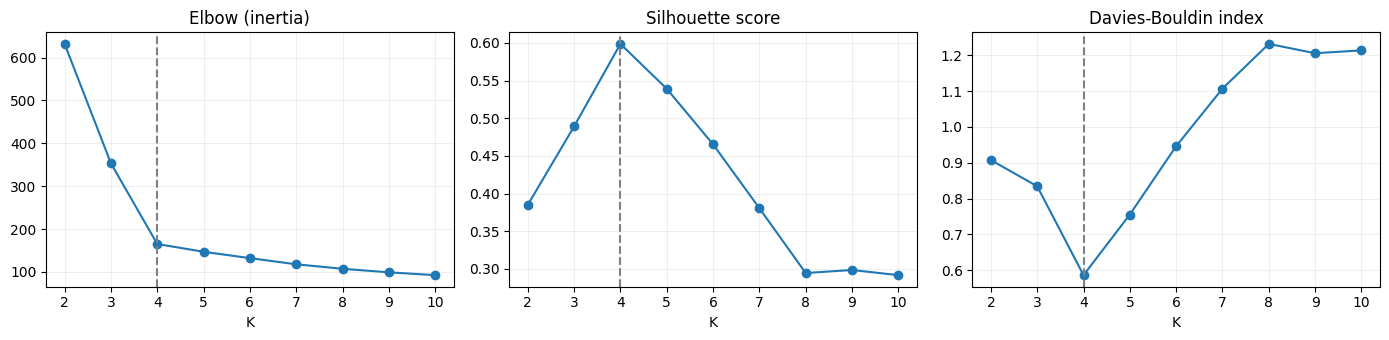

In [4]:
rows=[]
for k in range(2,11):
    km=KMeans(n_clusters=k,random_state=42,n_init=20)
    pred=km.fit_predict(X_scaled)
    rows.append({'K':k,'Inertia':km.inertia_,
                 'Silhouette':silhouette_score(X_scaled,pred),
                 'Davies-Bouldin':davies_bouldin_score(X_scaled,pred)})
metrics=pd.DataFrame(rows)
display(metrics.round(3))
best_k=int(metrics.loc[metrics['Silhouette'].idxmax(),'K'])
print('Selected K:',best_k)
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
for ax,col,title in zip(axes,['Inertia','Silhouette','Davies-Bouldin'],['Elbow (inertia)','Silhouette score','Davies-Bouldin index']):
    ax.plot(metrics['K'],metrics[col],marker='o');ax.axvline(best_k,color='gray',ls='--');ax.set(xlabel='K',title=title);ax.grid(alpha=.2)
plt.tight_layout();plt.show()

## 5. Fit final K-Means model

In [5]:
final_model=KMeans(n_clusters=best_k,random_state=42,n_init=20)
df['Cluster']=final_model.fit_predict(X_scaled)
print('Final inertia:',round(final_model.inertia_,2))
print('Final silhouette:',round(silhouette_score(X_scaled,df['Cluster']),3))
print('Final Davies-Bouldin:',round(davies_bouldin_score(X_scaled,df['Cluster']),3))
display(df.head())

Final inertia: 164.97
Final silhouette: 0.599
Final Davies-Bouldin: 0.586


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,26,16.6,87,2
1,2,31,15.0,62,2
2,3,25,24.5,78,2
3,4,18,37.7,87,2
4,5,24,40.4,84,2


## 6. Visualize clusters using PCA
PCA is used only to show the standardized 3D data in 2D; K-Means is fitted on all three scaled features.

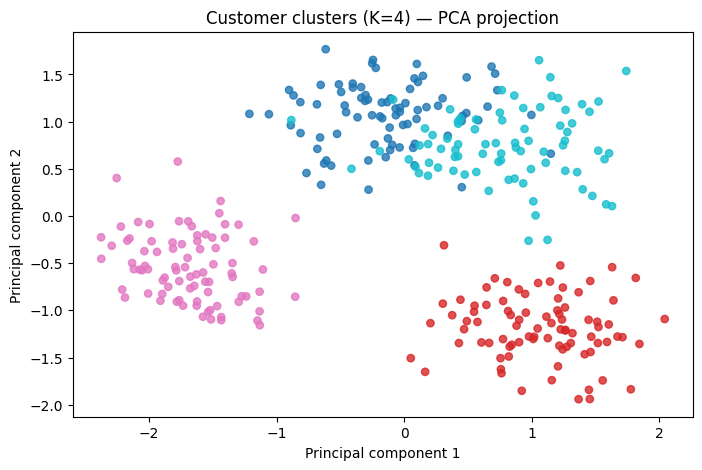

Explained variance: [0.454 0.324]


In [6]:
pca=PCA(n_components=2)
coords=pca.fit_transform(X_scaled)
plt.figure(figsize=(8,5))
plt.scatter(coords[:,0],coords[:,1],c=df['Cluster'],cmap='tab10',s=28,alpha=.8)
plt.xlabel('Principal component 1');plt.ylabel('Principal component 2')
plt.title(f'Customer clusters (K={best_k}) — PCA projection')
plt.show()
print('Explained variance:',np.round(pca.explained_variance_ratio_,3))

## 7. Silhouette plot
A silhouette value near 1 means well-separated, near 0 means overlapping, and below 0 suggests potential misassignment.

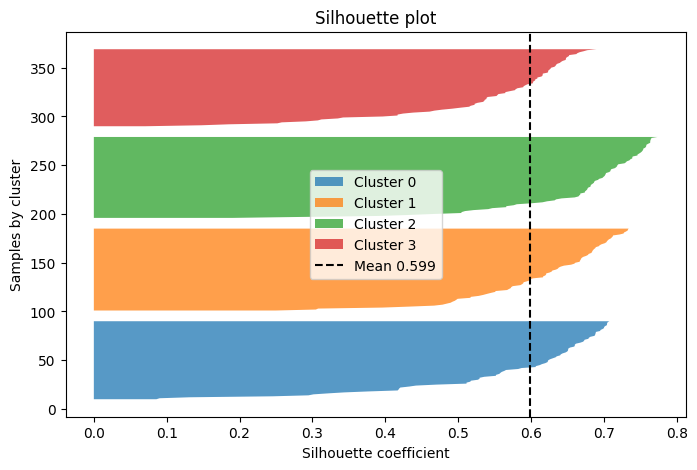

In [7]:
s=silhouette_samples(X_scaled,df['Cluster'])
fig,ax=plt.subplots(figsize=(8,5));lower=10
for c in range(best_k):
    vals=np.sort(s[df['Cluster']==c]);upper=lower+len(vals)
    ax.fill_betweenx(np.arange(lower,upper),0,vals,alpha=.75,label=f'Cluster {c}')
    lower=upper+10
avg=silhouette_score(X_scaled,df['Cluster'])
ax.axvline(avg,color='black',ls='--',label=f'Mean {avg:.3f}')
ax.set(xlabel='Silhouette coefficient',ylabel='Samples by cluster',title='Silhouette plot')
ax.legend();plt.show()

## 8. Profile and interpret each customer segment
Cluster numbers are arbitrary; use the feature means to give meaningful marketing descriptions.

In [8]:
profile=df.groupby('Cluster').agg(
    Size=('CustomerID','size'),Mean_Age=('Age','mean'),
    Mean_Income_k=('Annual Income (k$)','mean'),
    Mean_Spending=('Spending Score (1-100)','mean')).round(1)
display(profile)
print('Interpretation: high income/high spending = premium loyal; high income/low spending = potential upsell; low income/high spending = promotion-responsive; low income/low spending = budget-conscious. Confirm each cluster by its means.')

,Size,Mean_Age,Mean_Income_k,Mean_Spending
Cluster,,,,
0,81,46.5,80.9,84.0
1,85,55.3,31.6,24.1
2,84,24.0,27.6,77.2
3,80,36.9,86.6,19.8


Interpretation: high income/high spending = premium loyal; high income/low spending = potential upsell; low income/high spending = promotion-responsive; low income/low spending = budget-conscious. Confirm each cluster by its means.


## 9. Effect of scaling on K-Means
Fit a second K-Means model on raw features with the same K. Compare cluster membership using Adjusted Rand Index (ARI); 1 means identical partitions, about 0 indicates random-level agreement. Compare silhouette values only in their respective feature spaces.

ARI (scaled vs raw): 0.984
Scaled silhouette (scaled space): 0.599
Raw silhouette (raw space): 0.618


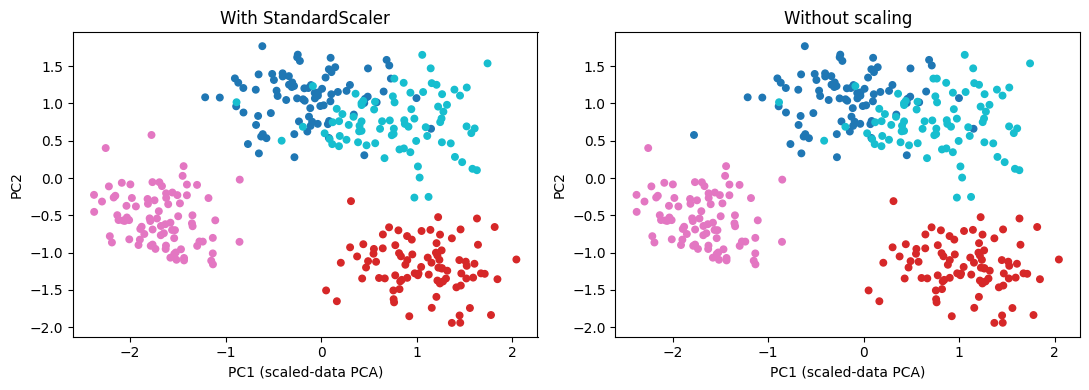

In [9]:
unscaled=KMeans(n_clusters=best_k,random_state=42,n_init=20)
raw_labels=unscaled.fit_predict(X)
ari=adjusted_rand_score(df['Cluster'],raw_labels)
print('ARI (scaled vs raw):',round(ari,3))
print('Scaled silhouette (scaled space):',round(silhouette_score(X_scaled,df['Cluster']),3))
print('Raw silhouette (raw space):',round(silhouette_score(X,raw_labels),3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,lab,title in zip(axes,[df['Cluster'],raw_labels],['With StandardScaler','Without scaling']):
    ax.scatter(coords[:,0],coords[:,1],c=lab,cmap='tab10',s=22)
    ax.set(title=title,xlabel='PC1 (scaled-data PCA)',ylabel='PC2')
plt.tight_layout();plt.show()

## 10. Conclusion and limitations
K-Means can discover interpretable segments without labels. Standardization is important because distances drive cluster formation. The chosen K is a data-dependent trade-off, not an objective truth. PCA is a projection and can hide separation in the original space. Synthetic data are useful for learning but real mall marketing decisions require real data, consent, privacy protection, and testing whether segments are stable and actionable.

In [10]:
# Optional: export the customer-level segment assignments
try:
    from google.colab import files
except ImportError:
    files = None  # Running outside Colab
output='mall_customers_clustered.csv'
df.to_csv(output,index=False)
print('Saved',output)
# files.download(output)  # Uncomment to download from Colab

Saved mall_customers_clustered.csv
